In [2]:
#!pip install torch
import torch

print("CUDA disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA disponível: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## Imports

In [1]:
import os
import imageio
import albumentations as A
import random
import numpy as np
import nibabel as nib
import multiprocessing as mp
import matplotlib.pyplot as plt
import pytorch_lightning as pl
import pandas as pd
import SimpleITK as sitk

W1124 15:56:09.058000 20272 site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


In [ ]:
from math import nan
from typing import List, Dict, Union
from glob import iglob, glob
from tqdm import tqdm
from argparse import Namespace
from torch import nn, Tensor
from torch.utils.data import Dataset, DataLoader
from torch.nn import functional as F
from torch.optim import Adam
from torchvision import datasets, transforms
from torchvision.utils import make_grid
from torchvision.transforms import Compose
from typing import Tuple
from pytorch_lightning import LightningDataModule
from pathlib import Path

In [ ]:
from matplotlib.patches import Patch
from scipy.ndimage import binary_erosion
from scipy.spatial import cKDTree

In [ ]:
from nibabel.processing import resample_from_to
import torchio as tio
import copy

In [ ]:
import torch.nn as nn
from transformers import AutoTokenizer, AutoModel
from torch.optim.lr_scheduler import CosineAnnealingLR
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping
from pytorch_lightning.loggers import CSVLogger

In [ ]:
# Check libraries version!
print(f"PyTorch version: {torch.__version__}")
print(f"Pytorch Lightning version: {pl.__version__}")

PyTorch version: 2.14.0+cu126
Pytorch Lightning version: 2.6.6


## Download e Análise do Dataset



**Exames:**
* ad -> Alzheimer's Disease (doença de Alzheimer)
* cn -> Cognitively Normal (indivíduos cognitivamente normais)
* mci -> Mild Cognitive Impairment (comprometimento cognitivo leve)

**Máscaras divididas em:**
* Esquerda (L)
* Direita (R)
* Bilateral (all)



In [ ]:
caminho = "C:/users/joaov/Downloads/projeto_final_ia025"

print(os.listdir(caminho))

['@Recently-Snapshot', 'comandos_segmentacao.csv', 'exemplo_segmentação_hip.png', 'masks', 'samples']


In [ ]:
print(os.listdir(caminho + "/samples"))
print(os.listdir(caminho + "/samples/ad"))
print(os.listdir(caminho + "/samples/cn"))
print(os.listdir(caminho + "/samples/mci"))

['ad', 'cn', 'mci']
['002_S_0816.nii.gz', '002_S_0938.nii.gz', '003_S_1059.nii.gz', '003_S_1257.nii.gz', '003_S_4136.nii.gz', '003_S_4142.nii.gz', '005_S_0221.nii.gz', '005_S_1341.nii.gz', '006_S_4192.nii.gz', '007_S_1304.nii.gz', '009_S_1334.nii.gz', '011_S_0010.nii.gz', '011_S_0183.nii.gz', '012_S_0689.nii.gz', '013_S_0592.nii.gz', '016_S_0991.nii.gz', '016_S_1263.nii.gz', '018_S_4696.nii.gz', '019_S_4252.nii.gz', '019_S_4549.nii.gz', '020_S_0213.nii.gz', '023_S_0139.nii.gz', '023_S_0916.nii.gz', '023_S_1289.nii.gz', '027_S_1081.nii.gz', '027_S_1385.nii.gz', '031_S_1209.nii.gz', '067_S_0812.nii.gz', '067_S_1185.nii.gz', '067_S_1253.nii.gz', '082_S_1079.nii.gz', '094_S_4089.nii.gz', '098_S_0149.nii.gz', '100_S_1062.nii.gz', '123_S_0088.nii.gz', '123_S_0091.nii.gz', '123_S_0094.nii.gz', '123_S_0162.nii.gz', '126_S_0606.nii.gz', '126_S_0784.nii.gz', '127_S_0754.nii.gz', '127_S_0844.nii.gz', '130_S_0956.nii.gz', '130_S_4730.nii.gz', '131_S_0691.nii.gz', 'e2dhipseg_masks']
['002_S_0295.ni

In [ ]:
print(os.listdir(caminho + "/masks"))
print(os.listdir(caminho + "/masks/ad"))
print(os.listdir(caminho + "/masks/all"))
print(os.listdir(caminho + "/masks/cn"))
print(os.listdir(caminho + "/masks/mci"))

['ad', 'all', 'all_aligned', 'check_class_harp.py', 'cn', 'mci']
['002_S_0816_L.nii.gz', '002_S_0816_R.nii.gz', '002_S_0938_L.nii.gz', '002_S_0938_R.nii.gz', '003_S_1059_L.nii.gz', '003_S_1059_R.nii.gz', '003_S_1257_L.nii.gz', '003_S_1257_R.nii.gz', '003_S_4136_L.nii.gz', '003_S_4136_R.nii.gz', '003_S_4142_L.nii.gz', '003_S_4142_R.nii.gz', '005_S_0221_L.nii.gz', '005_S_0221_R.nii.gz', '005_S_1341_L.nii.gz', '005_S_1341_R.nii.gz', '006_S_4192_L.nii.gz', '006_S_4192_R.nii.gz', '007_S_1304_L.nii.gz', '007_S_1304_R.nii.gz', '009_S_1334_L.nii.gz', '009_S_1334_R.nii.gz', '011_S_0010_L.nii.gz', '011_S_0010_R.nii.gz', '011_S_0183_L.nii.gz', '011_S_0183_R.nii.gz', '012_S_0689_L.nii.gz', '012_S_0689_R.nii.gz', '013_S_0592_L.nii.gz', '013_S_0592_R.nii.gz', '016_S_0991_L.nii.gz', '016_S_0991_R.nii.gz', '016_S_1263_L.nii.gz', '016_S_1263_R.nii.gz', '018_S_4696_L.nii.gz', '018_S_4696_R.nii.gz', '019_S_4252_L.nii.gz', '019_S_4252_R.nii.gz', '019_S_4549_L.nii.gz', '019_S_4549_R.nii.gz', '020_S_0213_L.

In [3]:
harp_path = Path("C:/users/joaov/Downloads/projeto_final_ia025")

pastas = [
    "samples/ad",
    "samples/cn",
    "samples/mci",
    "masks/ad",
    "masks/cn",
    "masks/mci",
    "masks/all"
]

for pasta in pastas:
    caminho = harp_path / pasta

    arquivos = [f for f in caminho.iterdir() if f.is_file()]

    print(f"\n{pasta}")
    print("Quantidade de arquivos:", len(arquivos))

    for arquivo in arquivos[:5]:
        print("  ", arquivo.name)


samples/ad
Quantidade de arquivos: 45
   002_S_0816.nii.gz
   002_S_0938.nii.gz
   003_S_1059.nii.gz
   003_S_1257.nii.gz
   003_S_4136.nii.gz

samples/cn
Quantidade de arquivos: 44
   002_S_0295.nii.gz
   002_S_0413.nii.gz
   002_S_0559.nii.gz
   002_S_0685.nii.gz
   002_S_1261.nii.gz

samples/mci
Quantidade de arquivos: 46
   002_S_0729.nii.gz
   002_S_0782.nii.gz
   002_S_0954.nii.gz
   002_S_1070.nii.gz
   002_S_1155.nii.gz

masks/ad
Quantidade de arquivos: 90
   002_S_0816_L.nii.gz
   002_S_0816_R.nii.gz
   002_S_0938_L.nii.gz
   002_S_0938_R.nii.gz
   003_S_1059_L.nii.gz

masks/cn
Quantidade de arquivos: 89
   002_S_0295_L.nii.gz
   002_S_0295_R.nii.gz
   002_S_0413_L.nii.gz
   002_S_0413_R.nii.gz
   002_S_0559_L.nii.gz

masks/mci
Quantidade de arquivos: 92
   002_S_0729_L.nii.gz
   002_S_0729_R.nii.gz
   002_S_0782_L.nii.gz
   002_S_0782_R.nii.gz
   002_S_0954_L.nii.gz

masks/all
Quantidade de arquivos: 135
   002_S_0295.nii.gz
   002_S_0413.nii.gz
   002_S_0559.nii.gz
   002_S

In [ ]:
ids = set()

for grupo in ["ad", "cn", "mci"]:
    pasta = harp_path / "samples" / grupo

    for arquivo in pasta.glob("*.nii.gz"):
        ids.add(arquivo.name.replace(".nii.gz", ""))

print("Total de identificadores únicos:", len(ids))

Total de identificadores únicos: 135


In [ ]:
for grupo in ["ad", "cn", "mci"]:

    samples = harp_path / "samples" / grupo
    masks = harp_path / "masks" / grupo

    imagens = {f.name.replace(".nii.gz", ""): f
               for f in samples.glob("*.nii.gz")}

    mascaras_L = {f.name.replace("_L.nii.gz", ""): f
                  for f in masks.glob("*_L.nii.gz")}

    mascaras_R = {f.name.replace("_R.nii.gz", ""): f
                  for f in masks.glob("*_R.nii.gz")}

    ids_imagens = set(imagens)
    ids_L = set(mascaras_L)
    ids_R = set(mascaras_R)

    print(f"\n==== GRUPO {grupo.upper()} =====")
    print("Imagens:", len(ids_imagens))
    print("Máscaras L:", len(ids_L))
    print("Máscaras R:", len(ids_R))

    print("Sem máscara esquerda:", ids_imagens - ids_L)
    print("Sem máscara direita:", ids_imagens - ids_R)
    print("Máscaras sem imagem:", (ids_L | ids_R) - ids_imagens)


==== GRUPO AD =====
Imagens: 45
Máscaras L: 45
Máscaras R: 45
Sem máscara esquerda: set()
Sem máscara direita: set()
Máscaras sem imagem: set()

==== GRUPO CN =====
Imagens: 44
Máscaras L: 44
Máscaras R: 44
Sem máscara esquerda: set()
Sem máscara direita: set()
Máscaras sem imagem: set()

==== GRUPO MCI =====
Imagens: 46
Máscaras L: 46
Máscaras R: 46
Sem máscara esquerda: set()
Sem máscara direita: set()
Máscaras sem imagem: set()


In [ ]:
grupo = "cn"
participante = "002_S_0295"

imagem = nib.load(f"C:/Users/joaov/Downloads/projeto_final_ia025/samples/{grupo}/{participante}.nii.gz")

mask_L = nib.load(f"C:/Users/joaov/Downloads/projeto_final_ia025/masks/{grupo}/{participante}_L.nii.gz")

mask_R = nib.load(f"C:/Users/joaov/Downloads/projeto_final_ia025/masks/{grupo}/{participante}_R.nii.gz")

mask_all = nib.load(f"C:/Users/joaov/Downloads/projeto_final_ia025/masks/all/{participante}.nii.gz")

arquivos = {
    "Imagem T1": imagem,
    "Máscara esquerda": mask_L,
    "Máscara direita": mask_R,
    "Máscara bilateral": mask_all
}

for nome, arquivo in arquivos.items():

    dados = arquivo.get_fdata()

    print(f"\n{nome}")
    print("Dimensões:", dados.shape)
    print("Espaçamento:", arquivo.header.get_zooms())
    print("Orientação:", nib.aff2axcodes(arquivo.affine))
    print("Valores únicos:", np.unique(dados))

    print(
        "Alinhamento com imagem:",
        np.allclose(arquivo.affine, imagem.affine)
    )


Imagem T1
Dimensões: (197, 233, 189)
Espaçamento: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Orientação: ('R', 'A', 'S')
Valores únicos: [0.0000e+00 1.0000e+00 2.0000e+00 ... 1.6667e+04 1.6695e+04 1.7004e+04]
Alinhamento com imagem: True

Máscara esquerda
Dimensões: (197, 233, 189)
Espaçamento: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Orientação: ('R', 'A', 'S')
Valores únicos: [0. 1.]
Alinhamento com imagem: True

Máscara direita
Dimensões: (197, 233, 189)
Espaçamento: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Orientação: ('R', 'A', 'S')
Valores únicos: [0. 1.]
Alinhamento com imagem: True

Máscara bilateral
Dimensões: (197, 233, 189)
Espaçamento: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Orientação: ('L', 'A', 'S')
Valores únicos: [0. 1.]
Alinhamento com imagem: False


In [ ]:
from nibabel.processing import resample_from_to

# Diretório de saída
pasta_saida = harp_path / "masks" / "all_aligned"
pasta_saida.mkdir(exist_ok=True)

# Contadores
total = 0
sucesso = 0
erros = []
resultados = []

for grupo in ["ad", "cn", "mci"]:
    pasta_imagens = harp_path / "samples" / grupo

    for imagem_path in sorted(pasta_imagens.glob("*.nii.gz")):
        id_paciente = imagem_path.name.replace(".nii.gz", "")
        mascara_path = harp_path / "masks" / "all" / f"{id_paciente}.nii.gz"
        total += 1

        try:
            # Verificar existência da máscara
            if not mascara_path.exists():
                raise FileNotFoundError(
                    f"Máscara não encontrada: {mascara_path}"
                )

            # Carregar imagem e máscara
            imagem = nib.load(str(imagem_path))
            mascara = nib.load(str(mascara_path))

            # Reamostrar máscara para o espaço da imagem T1
            mascara_alinhada = resample_from_to(
                mascara,
                (imagem.shape, imagem.affine),
                order=0
            )

            # Converter máscara para valores binários
            dados = mascara_alinhada.get_fdata()
            dados = (dados > 0.5).astype(np.uint8)

            # Verificar se a máscara não está vazia
            if np.sum(dados) == 0:
                raise ValueError("Máscara vazia após reamostragem")

            # Criar novo NIfTI usando a geometria da imagem
            header = imagem.header.copy()
            header.set_data_dtype(np.uint8)

            mascara_corrigida = nib.Nifti1Image(
                dados,
                imagem.affine,
                header
            )

            # Salvar máscara corrigida
            saida = pasta_saida / f"{id_paciente}.nii.gz"
            nib.save(mascara_corrigida, str(saida))

            # Verificações
            dimensoes_ok = mascara_corrigida.shape == imagem.shape

            affine_ok = np.allclose(
                mascara_corrigida.affine,
                imagem.affine
            )

            valores_ok = set(np.unique(dados)).issubset({0, 1})

            orientacao_ok = (
                nib.aff2axcodes(mascara_corrigida.affine)
                == nib.aff2axcodes(imagem.affine)
            )

            if not all([
                dimensoes_ok,
                affine_ok,
                valores_ok,
                orientacao_ok
            ]):
                raise ValueError("Falha na verificação geométrica ou binária")

            sucesso += 1

            resultados.append({
                "ID": id_paciente,
                "Grupo": grupo.upper(),
                "Dimensões": dimensoes_ok,
                "Affine": affine_ok,
                "Orientação": orientacao_ok,
                "Binária": valores_ok,
                "Voxels segmentados": int(np.sum(dados)),
                "Status": "OK"
            })

        except Exception as e:

            erros.append({
                "ID": id_paciente,
                "Grupo": grupo.upper(),
                "Erro": str(e)
            })

            print(f"ERRO - {id_paciente}: {e}")

print("\n==== RESULTADO ====")
print("Total de exames:", total)
print("Máscaras corrigidas:", sucesso)
print("Falhas:", len(erros))
print("Pasta de saída:", pasta_saida)


==== RESULTADO ====
Total de exames: 135
Máscaras corrigidas: 135
Falhas: 0
Pasta de saída: C:\users\joaov\Downloads\projeto_final_ia025\masks\all_aligned


In [ ]:
df_resultados = pd.DataFrame(resultados)

display(df_resultados)

print("\nDistribuição por grupo:")
print(df_resultados["Grupo"].value_counts())

print("\nVerificações:")
print(df_resultados[[
    "Dimensões",
    "Affine",
    "Orientação",
    "Binária"
]].all())

,ID,Grupo,Dimensões,Affine,Orientação,Binária,Voxels segmentados,Status
0,002_S_0816,AD,True,True,True,True,5287,OK
1,002_S_0938,AD,True,True,True,True,3569,OK
2,003_S_1059,AD,True,True,True,True,4476,OK
3,003_S_1257,AD,True,True,True,True,5984,OK
4,003_S_4136,AD,True,True,True,True,6857,OK
...,...,...,...,...,...,...,...,...
130,127_S_0397,MCI,True,True,True,True,5301,OK
131,131_S_0384,MCI,True,True,True,True,6457,OK
132,131_S_1389,MCI,True,True,True,True,4574,OK
133,136_S_0429,MCI,True,True,True,True,6281,OK



Distribuição por grupo:
Grupo
MCI    46
AD     45
CN     44
Name: count, dtype: int64

Verificações:
Dimensões     True
Affine        True
Orientação    True
Binária       True
dtype: bool


In [ ]:
if erros:
    print("Exames com problemas:")
    for erro in erros:
        print(erro)
else:
    print("Todas as 135 máscaras foram corrigidas e verificadas!")

Todas as 135 máscaras foram corrigidas e verificadas!


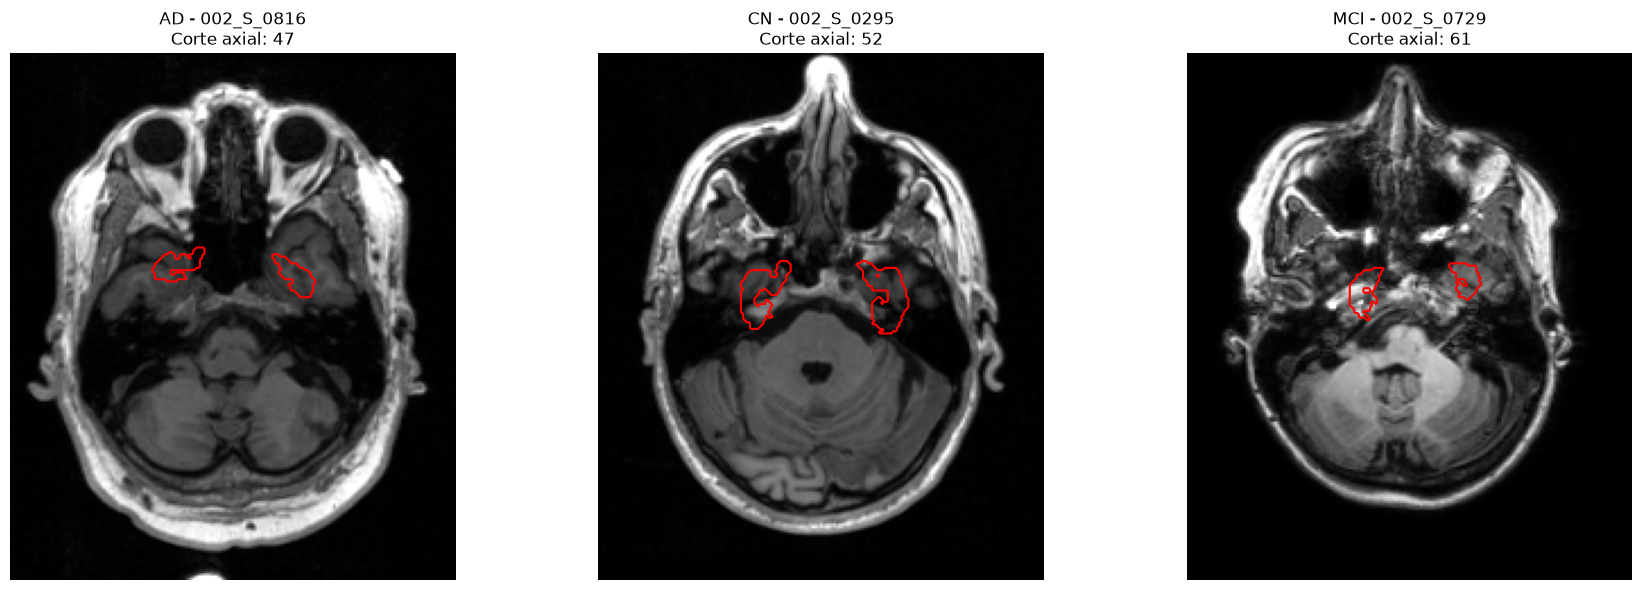

In [ ]:
grupos = ["ad", "cn", "mci"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, grupo in zip(axes, grupos):

    # Selecionar primeiro exame do grupo
    pasta = harp_path / "samples" / grupo
    arquivos = sorted(pasta.glob("*.nii.gz"))

    imagem_path = arquivos[0]
    id_paciente = imagem_path.name.replace(".nii.gz", "")

    # Carregar imagem e máscara alinhada
    imagem = nib.load(str(imagem_path)).get_fdata()

    mascara_path = (
        harp_path / "masks" / "all_aligned" / f"{id_paciente}.nii.gz"
    )

    mascara = nib.load(str(mascara_path)).get_fdata()

    # Encontrar corte axial com maior quantidade de voxels segmentados
    voxels_por_corte = np.sum(mascara > 0, axis=(0, 1))
    indice_corte = np.argmax(voxels_por_corte)

    # Extrair os cortes
    imagem_corte = imagem[:, :, indice_corte]
    mascara_corte = mascara[:, :, indice_corte]

    # Ajustar contraste da imagem
    valores = imagem_corte[imagem_corte > 0]

    vmin, vmax = np.percentile(valores, [1, 99])

    # Mostrar imagem T1
    ax.imshow(
        imagem_corte.T,
        cmap="gray",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )

    # Sobrepor contorno da máscara
    ax.contour(
        mascara_corte.T,
        levels=[0.5],
        colors = "red",
        linewidths=1.5
    )

    ax.set_title(
        f"{grupo.upper()} - {id_paciente}\n"
        f"Corte axial: {indice_corte}"
    )

    ax.axis("off")

plt.tight_layout()
plt.savefig("exemplo_segmentação_hip.png", dpi=150, bbox_inches="tight")
plt.show()


AD - 002_S_0816
Cortes selecionados: [38, 46, 52, 60, 66]

CN - 002_S_0295
Cortes selecionados: [46, 51, 56, 62, 67]

MCI - 002_S_0729
Cortes selecionados: [54, 60, 64, 70, 74]


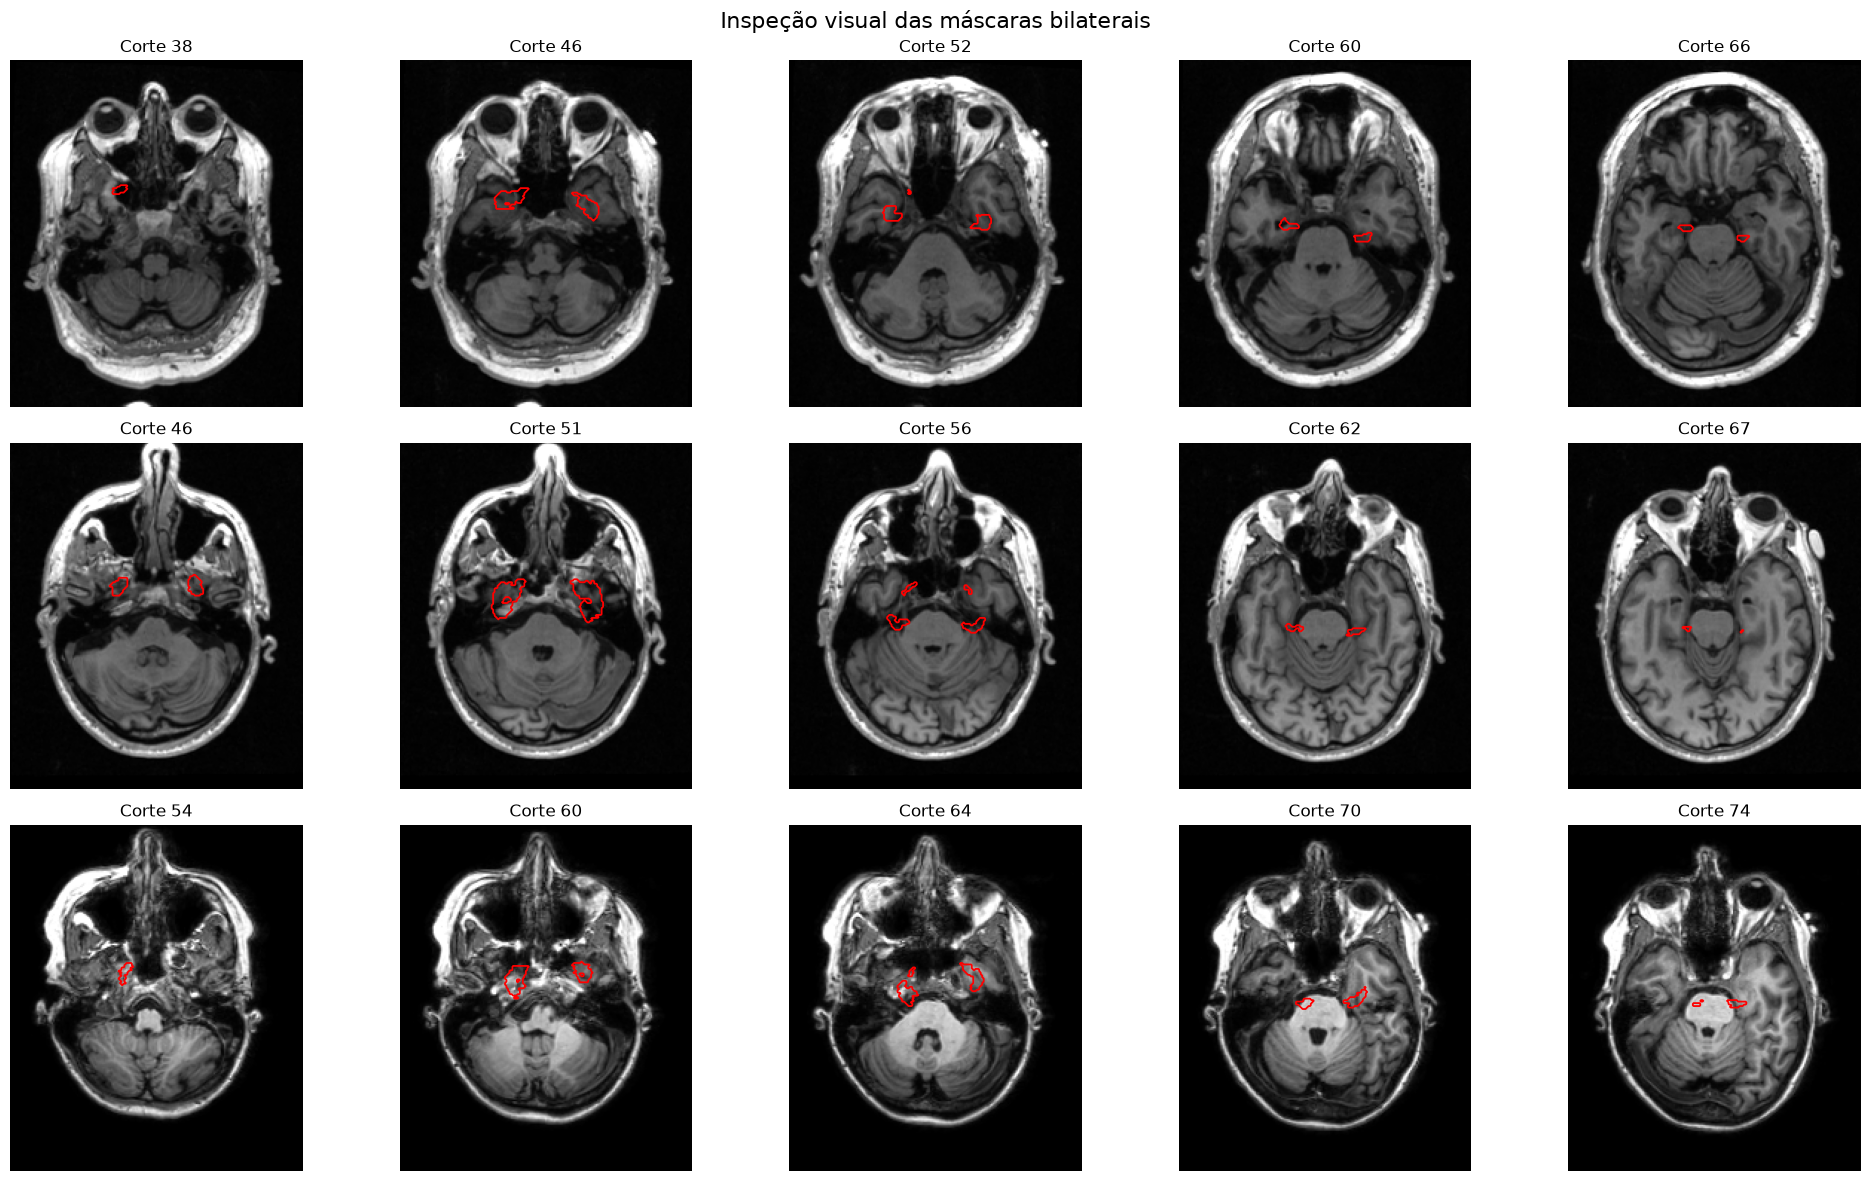

In [ ]:
participantes = {
    "AD": "002_S_0816",
    "CN": "002_S_0295",
    "MCI": "002_S_0729"
}

# 3 participantes x 5 cortes axiais
fig, axes = plt.subplots(3, 5, figsize=(20, 12))

for linha, (grupo, id_paciente) in enumerate(participantes.items()):

    # Localizar imagem T1
    imagem_path = (harp_path / "samples" / grupo.lower() / f"{id_paciente}.nii.gz")

    # Localizar máscara bilateral corrigida
    mascara_path = (harp_path / "masks" / "all_aligned" / f"{id_paciente}.nii.gz")

    # Carregar dados
    imagem_nii = nib.load(str(imagem_path))
    mascara_nii = nib.load(str(mascara_path))

    imagem = imagem_nii.get_fdata()
    mascara = mascara_nii.get_fdata()

    # Identificar cortes que possuem voxels segmentados
    voxels_por_corte = np.sum(mascara > 0, axis=(0, 1))

    cortes_validos = np.where(voxels_por_corte > 0)[0]

    # Selecionar cinco cortes distribuídos pela extensão do hipocampo
    quantis = np.linspace(0.1, 0.9, 5)

    cortes = np.quantile(cortes_validos, quantis).round().astype(int)

    # Evitar duplicação de índices
    cortes = np.unique(cortes)

    # Ajustar contraste da imagem
    valores = imagem[imagem > 0]
    vmin, vmax = np.percentile(valores, [1, 99])

    print(f"\n{grupo} - {id_paciente}")
    print("Cortes selecionados:", cortes.tolist())

    for coluna, indice in enumerate(cortes):
        ax = axes[linha, coluna]

        imagem_corte = imagem[:, :, indice]
        mascara_corte = mascara[:, :, indice]

        # Exibir imagem T1
        ax.imshow(
            imagem_corte.T,
            cmap="gray",
            origin="lower",
            vmin=vmin,
            vmax=vmax
        )

        # Sobrepor contorno da máscara
        if np.any(mascara_corte > 0):
            ax.contour(
                mascara_corte.T,
                levels=[0.5],
                linewidths=1.3,
                colors = "red"
            )

        ax.set_title(f"Corte {indice}")
        ax.axis("off")

    # Identificação do participante
    axes[linha, 0].set_ylabel(
        f"{grupo}\n{id_paciente}",
        fontsize=12,
        rotation=0,
        labelpad=75,
        va="center"
    )

plt.suptitle(
    "Inspeção visual das máscaras bilaterais",
    fontsize=16
)

plt.tight_layout()
plt.show()

#U-Net 3D Multimodal

In [4]:
class Dataset_Hipocampo(Dataset):
  def __init__(
      self,
      path: Path,
      normalization: bool = True,
      seed: int = 125,
      perc_treino: float = 0.7,
      perc_val: float = 0.1,
      getitem_mode: str = "train",
      caminho_prompts: str = "comandos_segmentacao.csv"
  ):
    self.path = Path(path)
    self.normalization = normalization
    self.mode = getitem_mode

    self.data_train = []
    self.data_val = []
    self.data_test = []

    self.diagnostics = {
        "ad": "Alzheimer's Disease",
        "cn": "Cognitively Normal",
        "mci": "Mild Cognitive Impairment"
    }

    # prompts textuais
    prompts_path = self.path / caminho_prompts
    df_prompts = pd.read_csv(prompts_path)

    self.text_prompts = {}
    for _, row in df_prompts.iterrows():
      grupo = (row.iloc[0].lower(), row.iloc[1].lower())
      texto = row.iloc[2]
      if grupo not in self.text_prompts:
        self.text_prompts[grupo] = []
      self.text_prompts[grupo].append(texto)

    # crop e data augmentation
    self.crop = tio.CropOrPad((128, 128, 128))
    self.cache_imgs = {}
    self.cache_masks = {}

    self.train_transforms = tio.Compose([
        tio.RandomAffine(
            scales = (0.9, 1.1),
            degrees = 10,
            translation = 5,
            image_interpolation = "linear",
            label_interpolation = "nearest",
            p = 0.5
        ),
        tio.RandomNoise(std = 0.05),
        tio.RandomGamma(log_gamma = (-0.2, 0.2))
    ])

    for grupo in ["ad", "cn", "mci"]:
      imagens_path = self.path / "samples" / grupo
      mascaras_path = self.path / "masks" / grupo
      ambos_path = self.path / "masks" / "all_aligned"

      pacientes = sorted(
          [id.name.replace(".nii.gz", "") for id in imagens_path.glob("*.nii.gz")]
      )

      random.seed(seed)
      random.shuffle(pacientes)

      total_pacientes = len(pacientes)
      idx_treino = int(total_pacientes * perc_treino)
      idx_val = int(total_pacientes * (perc_treino + perc_val))

      for n, paciente_id in enumerate(pacientes):
        img_path = imagens_path / f"{paciente_id}.nii.gz"

        mascara_L = mascaras_path / f"{paciente_id}_L.nii.gz"
        mascara_R = mascaras_path / f"{paciente_id}_R.nii.gz"
        mascara_both = ambos_path / f"{paciente_id}.nii.gz"

        if mascara_L.exists() and mascara_R.exists():
          nii_L = nib.as_closest_canonical(nib.load(str(mascara_L)))
          nii_R = nib.as_closest_canonical(nib.load(str(mascara_R)))

          vox_L = np.argwhere(nii_L.get_fdata() > 0.5)
          vox_R = np.argwhere(nii_R.get_fdata() > 0.5)

          if len(vox_L) > 0 and len(vox_R) > 0:
            ras_x_L = nib.affines.apply_affine(nii_L.affine, vox_L)[:, 0].mean()
            ras_x_R = nib.affines.apply_affine(nii_R.affine, vox_R)[:, 0].mean()
            if ras_x_L > ras_x_R:
              mascara_L, mascara_R = mascara_R, mascara_L
              # por algum motivo tava lendo algumas invertidas,
              # procedimento para manter orientação correta

        if n < idx_treino:
          target = self.data_train
        elif n < idx_val:
          target = self.data_val
        else:
          target = self.data_test

        if mascara_L.exists():
          target.append({
              "id": paciente_id,
              "group": grupo,
              "img_path": str(img_path),
              "mask_path": str(mascara_L),
              "text": "left"
          })

        if mascara_R.exists():
          target.append({
              "id": paciente_id,
              "group": grupo,
              "img_path": str(img_path),
              "mask_path": str(mascara_R),
              "text": "right"
          })

        if mascara_both.exists():
          target.append({
              "id": paciente_id,
              "group": grupo,
              "img_path": str(img_path),
              "mask_path": str(mascara_both),
              "text": "both"
          })

  # divisão treino validação teste

  def change_mode(self, mode: str = "train"):
    self.mode = mode

  def extract_mode(self):
    if self.mode == "train":
      return self.data_train
    elif self.mode == "val":
      return self.data_val
    else:
      return self.data_test

  def __len__(self):
    return len(self.extract_mode())

  def __getitem__(self, idx, train_augmentation: bool = True):
    item = self.extract_mode()[idx]

    img_path = item["img_path"]
    mask_path = item["mask_path"]

    if img_path not in self.cache_imgs:
      img_nii = nib.as_closest_canonical(nib.load(img_path))
      img_np = img_nii.get_fdata()
      img_t = torch.from_numpy(img_np).unsqueeze(0).float()
      self.cache_imgs[img_path] = self.crop(tio.ScalarImage(tensor = img_t)).data

    if mask_path not in self.cache_masks:
      img_nii = nib.as_closest_canonical(nib.load(img_path))
      mask_nii = nib.as_closest_canonical(nib.load(mask_path))

      if mask_nii.shape != img_nii.shape or not np.allclose(mask_nii.affine, img_nii.affine):
        mask_nii = resample_from_to(mask_nii, (img_nii.shape, img_nii.affine), order = 0)

      mask_np = (mask_nii.get_fdata() > 0.5)
      mask_t = torch.from_numpy(mask_np).unsqueeze(0).to(torch.uint8)
      self.cache_masks[mask_path] = self.crop(tio.LabelMap(tensor = mask_t)).data

    imagem = self.cache_imgs[img_path].clone()
    mascara = self.cache_masks[mask_path].float()

    if self.mode == "train" and train_augmentation:
      subject = tio.Subject(
          img = tio.ScalarImage(tensor = imagem),
          mask = tio.LabelMap(tensor = mascara)
      )
      subject = self.train_transforms(subject)
      imagem = subject.img.data
      mascara = subject.mask.data

    if self.normalization:
      imagem = (imagem - torch.mean(imagem)) / (torch.std(imagem) + 1e-8)

    chave = (item["text"], item["group"])
    lista_prompts = self.text_prompts[chave]

    if self.mode == "train":
      prompt_texto = random.choice(lista_prompts)
    else:
      prompt_texto = lista_prompts[idx % len(lista_prompts)]

    return imagem, mascara, prompt_texto, item["group"]

In [5]:
class Datamodule_Hipocampo():
  def __init__(self,
               path: Path,
               hparams):
    self.path = path
    self.hparams = hparams

    data = Dataset_Hipocampo(
        path = self.path,
        normalization = True, #self.hparams["normalization"]
        seed = self.hparams["seed"],
        caminho_prompts = self.hparams["caminho_prompts"]
    )

    self.data_train = copy.copy(data)
    self.data_train.change_mode("train")

    self.data_val = copy.copy(data)
    self.data_val.change_mode("val")

    self.data_test = copy.copy(data)
    self.data_test.change_mode("test")

  def train_dataloader(self):
    return DataLoader(
        self.data_train,
        batch_size = self.hparams["batch_size"],
        shuffle = True
    )

  def val_dataloader(self):
    return DataLoader(
        self.data_val,
        batch_size = self.hparams["batch_size"],
        shuffle = False
    )

  def test_dataloader(self):
    return DataLoader(
        self.data_test,
        batch_size = self.hparams["batch_size"],
        shuffle = False
    )

In [6]:
class DoubleConv(nn.Module): # pegamos da atividade só mudamos para 3d
    """(convolution => [BN] => ReLU) * 2"""
    def __init__(self,
                 in_channels,
                 out_channels,
                 norm = True):
        super().__init__()
        layers = [
            nn.Conv3d(in_channels,
                      out_channels,
                      kernel_size = 3,
                      padding = 1,
                      bias = not norm),
        ]
        if norm:
            layers.append(nn.InstanceNorm3d(out_channels, affine = True))

        layers.append(nn.ReLU(inplace = True))

        layers.append(nn.Conv3d(out_channels,
                                out_channels,
                                kernel_size = 3,
                                padding = 1,
                                bias = not norm))
        if norm:
            layers.append(nn.InstanceNorm3d(out_channels, affine = True))
        layers.append(nn.ReLU(inplace = True))

        self.double_conv = nn.Sequential(*layers)

    def forward(self, x):
        return self.double_conv(x)

In [7]:
class UNet_3d(nn.Module):
  def __init__(
      self,
      hparams: dict
  ):
    super().__init__()

    c_i = hparams["canal_inicial"]
    norm = hparams["norm"]

      # encoder

    self.inc = DoubleConv(
        in_channels = hparams["n_channels"],
        out_channels = c_i,
        norm = norm
    )

    self.down1 = nn.Sequential(
        nn.MaxPool3d(kernel_size = 2),
        DoubleConv(
            in_channels = c_i,
            out_channels = c_i * 2,
            norm = norm
        )
    )

    self.down2 = nn.Sequential(
        nn.MaxPool3d(kernel_size = 2),
        DoubleConv(
            in_channels = c_i * 2,
            out_channels = c_i * 4,
            norm = norm
        )
    )

    self.down3 = nn.Sequential(
        nn.MaxPool3d(kernel_size = 2),
        DoubleConv(
            in_channels = c_i * 4,
            out_channels = c_i * 8,
            norm = norm
        )
    )

    self.down4 = nn.Sequential(
        nn.MaxPool3d(kernel_size = 2),
        DoubleConv(
            in_channels = c_i * 8,
            out_channels = min(c_i * 16, 320), # sugestao da nnu-net !!!!
            norm = norm
        )
    )

    self.down5 = nn.Sequential(
        nn.MaxPool3d(kernel_size = 2),
        DoubleConv(
            in_channels = min(c_i * 16, 320),
            out_channels = min(c_i * 32, 320),
            norm = norm
        )
    )

      # decoder

    self.up00 = nn.ConvTranspose3d(
        in_channels = min(c_i * 32, 320),
        out_channels = min(c_i * 16, 320),
        kernel_size = 2,
        stride = 2
    )
    self.conv_up00 = DoubleConv(
        in_channels = min(c_i * 32, 320)*2,
        out_channels = min(c_i * 16, 320),
        norm = norm
    )

    self.up0 = nn.ConvTranspose3d(
        in_channels = min(c_i * 16, 320),
        out_channels = c_i * 8,
        kernel_size = 2,
        stride = 2
    )
    self.conv_up0 = DoubleConv(
        in_channels = c_i * 16,
        out_channels = c_i * 8,
        norm = norm
    )

    self.up1 = nn.ConvTranspose3d(
        in_channels = c_i * 8,
        out_channels = c_i * 4,
        kernel_size = 2,
        stride = 2
    )
    self.conv_up1 = DoubleConv(
        in_channels = c_i * 8,
        out_channels = c_i * 4,
        norm = norm
    )

    self.up2 = nn.ConvTranspose3d(
        in_channels = c_i * 4,
        out_channels = c_i * 2,
        kernel_size = 2,
        stride = 2
    )
    self.conv_up2 = DoubleConv(
        in_channels = c_i * 4,
        out_channels = c_i * 2,
        norm = norm
    )

    self.up3 = nn.ConvTranspose3d(
        in_channels = c_i * 2,
        out_channels = c_i,
        kernel_size = 2,
        stride = 2
    )
    self.conv_up3 = DoubleConv(
        in_channels = c_i * 2,
        out_channels = c_i,
        norm = norm
    )

    self.outc = nn.Conv3d(
        in_channels = c_i,
        out_channels = 1,
        kernel_size = 1
    )

  def encode(self, x):
    x1 = self.inc(x)
    x2 = self.down1(x1)
    x3 = self.down2(x2)
    x4 = self.down3(x3)
    x5 = self.down4(x4)
    x6 = self.down5(x5)
    return x1, x2, x3, x4, x5, x6

  def decode(self, x1, x2, x3, x4, x5, x6):

    x = self.up00(x6)
    x = torch.cat([x5, x], dim = 1)
    x = self.conv_up00(x)

    x = self.up0(x)
    x = torch.cat([x4, x], dim = 1)
    x = self.conv_up0(x)

    x = self.up1(x)
    x = torch.cat([x3, x], dim = 1)
    x = self.conv_up1(x)

    x = self.up2(x)
    x = torch.cat([x2, x], dim = 1)
    x = self.conv_up2(x)

    x = self.up3(x)
    x = torch.cat([x1, x], dim = 1)
    x = self.conv_up3(x)

    return self.outc(x)

  def forward(self, x): # unet pura !!!!
    x1, x2, x3, x4, x5, x6 = self.encode(x)
    return self.decode(x1, x2, x3, x4, x5, x6)

In [8]:
class Cross_attention(nn.Module):
  def __init__(self, hparams):
    super().__init__()

    self.emb_size = min(hparams["canal_inicial"] * 32, 320)
    self.n_head = hparams["n_head"]
    self.head_dim = self.emb_size // self.n_head

    assert self.emb_size % self.n_head == 0, "n_head nao eh divisor de embedding_size"

    self.Q_proj = nn.Linear(self.emb_size, self.emb_size)
    self.K_proj = nn.Linear(self.emb_size, self.emb_size)
    self.V_proj = nn.Linear(self.emb_size, self.emb_size)
    self.output_proj = nn.Linear(self.emb_size, self.emb_size)
    self.norm = nn.LayerNorm(self.emb_size)

  def forward(self, q_input, kv_input):
    B, T_q, C = q_input.size()
    sla, T_kv, sla = kv_input.size()

    Q = self.Q_proj(q_input).view(B, T_q, self.n_head, self.head_dim).transpose(1, 2)
    K = self.K_proj(kv_input).view(B, T_kv, self.n_head, self.head_dim).transpose(1, 2)
    V = self.V_proj(kv_input).view(B, T_kv, self.n_head, self.head_dim).transpose(1, 2)

    output = F.scaled_dot_product_attention(Q, K, V)

    output = output.transpose(1, 2).contiguous().view(B, T_q, C)
    output = self.output_proj(output)

    return self.norm(q_input + output) # sugestao do gemini: conexao residual

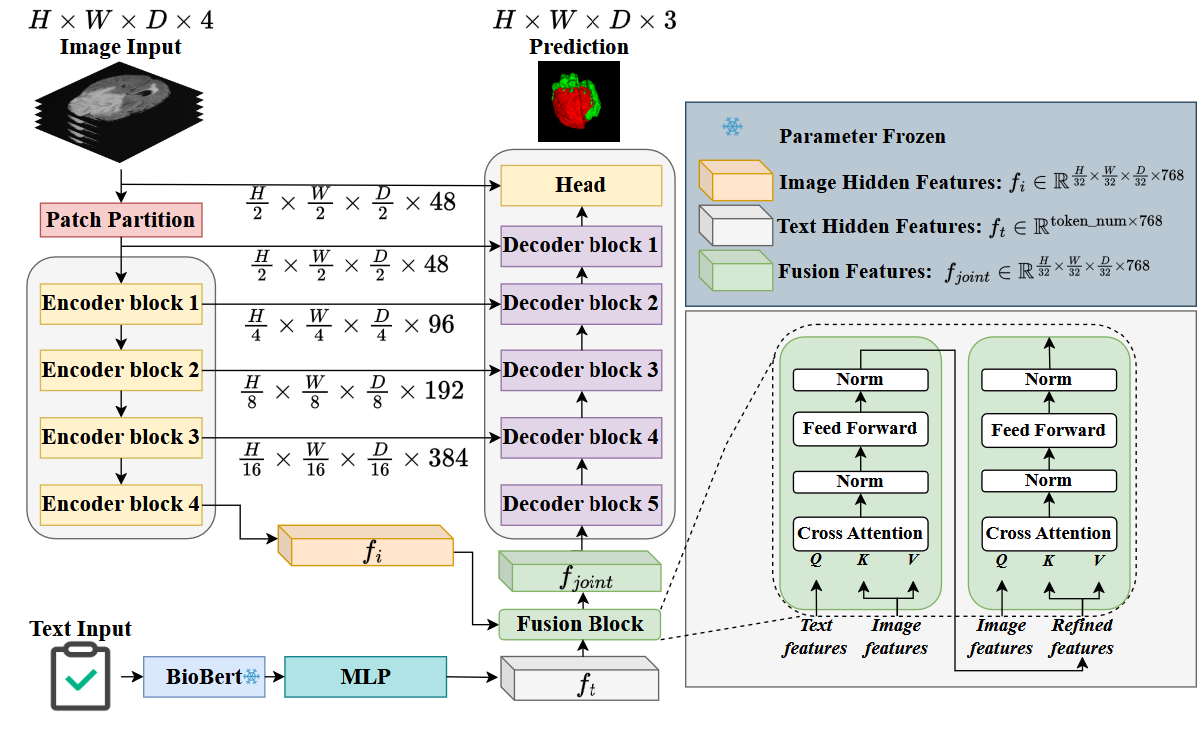

In [9]:
class TextBraTS_hipocampo(nn.Module):
  def __init__(
      self,
      hparams,
      text_model: str = "neuralmind/bert-base-portuguese-cased",
      #freeze_text: bool = True
  ):
    super().__init__()

    # parte textual

    self.tokenizer = AutoTokenizer.from_pretrained(text_model)
    self.text_encoder = AutoModel.from_pretrained(text_model)

    if hparams.get("freeze_text", True):
      for param in self.text_encoder.parameters():
        param.requires_grad = False

    emb_size = min(hparams["canal_inicial"] * 32, 320)

    self.mlp_text = nn.Sequential(
        nn.Linear(
                in_features = 768,
                out_features = hparams["hidden_layer"]
            ),
            nn.LayerNorm(hparams["hidden_layer"]),
            nn.GELU(),
            nn.Dropout(hparams["mlp_dropout"]),
            nn.Linear(
                in_features = hparams["hidden_layer"],
                out_features = emb_size
            )
    )

    # parte u-net 3d

    self.unet = UNet_3d(hparams)
    self.pos_emb_3d = nn.Parameter(torch.randn(1, 64, emb_size) * 0.02)

    # sequential cross-attention

    self.cross_attention1 = Cross_attention(hparams)
    self.cross_attention2 = Cross_attention(hparams)

  def forward(self, imagem, textos):

    device = imagem.device

    encoded_text = self.tokenizer(
        textos,
        padding = True,
        truncation = True,
        return_tensors = "pt"
    ).to(device)

    # encoder texto
    text_embeddings = self.text_encoder(**encoded_text).last_hidden_state
    text_embeddings = self.mlp_text(text_embeddings)

    # encoder imagem
    x1, x2, x3, x4, x5, x6 = self.unet.encode(imagem)
    B, C, D, H, W = x6.size()
    n_voxels = D * H * W
    image_embeddings = x6.view(B, C, n_voxels).transpose(1,2) + self.pos_emb_3d

    # sequential cross-attention
    x = self.cross_attention1(
        q_input = text_embeddings,
        kv_input = image_embeddings
    )

    x = self.cross_attention2(
        q_input = image_embeddings,
        kv_input = x
    )

    # decoder segmentação
    x6 = x.transpose(1,2).contiguous().view(B, C, D, H, W)
    return self.unet.decode(x1, x2, x3, x4, x5, x6)

In [10]:
class Loss(nn.Module):
  def __init__(
      self,
      peso_dice: float = 0.5
  ):
    super().__init__()

    self.peso_dice = peso_dice

  def forward(self, logits, labels):

    logits = logits.float()
    labels = labels.float()

    binary_entropy = torch.clamp(logits, min = 0) - logits*labels
    binary_entropy += torch.log(1 + torch.exp(-torch.abs(logits)))

    probabilidades = torch.sigmoid(logits)

    vetor_probs = probabilidades.view(-1)
    vetor_labels = labels.view(-1)

    dice = (2.0 * torch.dot(vetor_probs, vetor_labels))/(
        torch.sum(vetor_probs + vetor_labels) + 1e-6
    )

    dice = 1.0 - dice

    return (self.peso_dice * dice) + ((1.0 - self.peso_dice) * torch.mean(binary_entropy))

In [11]:
class Treinamento_hipocampo(pl.LightningModule):
  def __init__(self, hparams):
    super().__init__()

    self.save_hyperparameters(hparams)
    self.modelo = TextBraTS_hipocampo(self.hparams,
                                      text_model = self.hparams["text_model"])
    self.perda = Loss(peso_dice = self.hparams["peso_dice"])

  def forward(self, imagem, textos):
    return self.modelo(imagem, textos)

  def dice(self, logits, labels):
    logits = logits.float()
    labels = labels.float()
    probabilidades = torch.sigmoid(logits)
    vetor_probs = probabilidades.view(-1)
    vetor_labels = labels.view(-1)

    return (2.0 * torch.dot(vetor_probs, vetor_labels))/(
        torch.sum(vetor_probs + vetor_labels) + 1e-6
    )

  def passo(self, batch, batch_i, subconjunto):
    imagens, mascaras, textos, grupos = batch

    logits = self(imagens, textos)
    loss_batch = self.perda(logits, mascaras)
    dice_batch = self.dice(logits, mascaras)

    self.log(f"{subconjunto}_loss",
             loss_batch,
             on_step = False,
             on_epoch = True,
             prog_bar = True,
             batch_size = imagens.shape[0])
    self.log(f"{subconjunto}_dice",
             dice_batch,
             on_step = False,
             on_epoch = True,
             prog_bar = True,
             batch_size = imagens.shape[0])

    for grupo in ["ad", "cn", "mci"]:
      indices = [i for i, grp in enumerate(grupos) if grp == grupo]

      if len(indices) == 0: continue

      logitos_grupo = logits[indices]
      mascaras_grupo = mascaras[indices]

      loss_grupo = self.perda(logitos_grupo, mascaras_grupo)
      dice_grupo = self.dice(logitos_grupo, mascaras_grupo)

      self.log(f"{subconjunto}_loss_{grupo}",
               loss_grupo,
               on_step = False,
               on_epoch = True,
               batch_size = len(indices))
      self.log(f"{subconjunto}_dice_{grupo}",
               dice_grupo,
               on_step = False,
               on_epoch = True,
               batch_size = len(indices))
    return loss_batch

  def training_step(self, batch, batch_i):
    return self.passo(batch, batch_i, "treino")

  def validation_step(self, batch, batch_i):
    return self.passo(batch, batch_i, "val")

  def test_step(self, batch, batch_i):
    return self.passo(batch, batch_i, "teste")

  def configure_optimizers(self):
    otimizador = torch.optim.AdamW(
        self.parameters(),
        lr = self.hparams["learning_rate"],
        weight_decay = self.hparams["weight_decay"]
    )

    esquema = {
        "scheduler": CosineAnnealingLR(
            otimizador,
            T_max = self.hparams["max_epochs"],
            eta_min = 1e-6
        ),
        "interval": "epoch",
        "frequency": 1
    }

    return [otimizador], [esquema]

In [12]:
hyperparameters = {
    "n_channels": 1,
    "canal_inicial": 32,
    "norm": True,

    "hidden_layer": 256,
    "mlp_dropout": 0.1,
    "n_head": 4,

    "batch_size": 2,
    "learning_rate": 3e-4,
    "weight_decay": 1e-4,
    "peso_dice": 0.9,
    "seed": 125,
    "max_epochs": 10,
    "patience": 30,
    "freeze_text": True,

    "caminho_prompts": "comandos_segmentacao.csv",
    "text_model": "neuralmind/bert-base-portuguese-cased"
}

In [ ]:
datamodule = Datamodule_Hipocampo(path = harp_path,
                                  hparams = hyperparameters)
modelo = Treinamento_hipocampo(hyperparameters)

checkpoint_callback = ModelCheckpoint(
    dirpath = "modelo_salvos/",
    filename = "multimodal_hipocampo_{epoch:02d}_{val_loss:.4f}",
    monitor = "val_loss",
    mode = "min",
    save_top_k = 1
)

logger = CSVLogger("logs_treino/", name = "unet_multimodal")

trainer = pl.Trainer(
    max_epochs = hyperparameters["max_epochs"],
    accelerator = "gpu" if torch.cuda.is_available() else "cpu",
    devices = 1,
    precision = "16-mixed",
    callbacks = [checkpoint_callback],
    gradient_clip_val = 1.0,
    logger = logger
)

trainer.fit(
    model = modelo,
    train_dataloaders = datamodule.train_dataloader(),
    val_dataloaders = datamodule.val_dataloader()
)

# TESTE!!
print("TESTE!!")

trainer.test(
    model = modelo,
    dataloaders = datamodule.test_dataloader(),
    ckpt_path = "best"
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.

KeyboardInterrupt


KeyboardInterrupt



In [ ]:
# tentativa de fine-tuning...

ckpt_path = "modelo_salvos/multimodal_hipocampo_epoch=169_val_loss=0.2491.ckpt"

datamodule = Datamodule_Hipocampo(
    path = harp_path,
    hparams = hyperparameters
)
modelo = Treinamento_hipocampo.load_from_checkpoint(ckpt_path)

for nome, param in modelo.named_parameters():
    if "text_encoder" in nome or "mlp_text" in nome:
        param.requires_grad = True
    else:
        param.requires_grad = False

epochs_finetuning = 10
modelo.hparams["learning_rate"] = 3e-5
modelo.hparams["max_epochs"] = epochs_finetuning
modelo.hparams["freeze_text"] = False

checkpoint_callback = ModelCheckpoint(
    dirpath = "modelo_salvos/pos_finetuning/",
    filename = "hipocampo_ft_texto_{epoch:02d}_{val_loss:.4f}",
    monitor = "val_loss",
    mode = "min",
    save_top_k = 1,
    save_last = True
)

logger = CSVLogger("logs_treino/", name = "unet_multimodal_ft_texto")

trainer_ft = pl.Trainer(
    max_epochs = epochs_finetuning,
    accelerator = "gpu" if torch.cuda.is_available() else "cpu",
    devices = 1,
    precision = "16-mixed",
    callbacks = [checkpoint_callback],
    gradient_clip_val = 1.0,
    logger = logger
)

trainer_ft.fit(
    model = modelo,
    train_dataloaders = datamodule.train_dataloader(),
    val_dataloaders = datamodule.val_dataloader()
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment track

┏━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name   ┃ Type                ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ modelo │ TextBraTS_hipocampo │  141 M │ train │     0 │
│ 1 │ perda  │ Loss                │      0 │ train │     0 │
└───┴────────┴─────────────────────┴────────┴───────┴───────┘

Trainable params: 32.3 M                                                                                           
Non-trainable params: 108 M                                                                                        
Total params: 141 M                                                                                                
Total estimated model params size (MB): 564.946                                                                    
Modules in train mode: 125                                                                                         
Modules in eval mode: 228                                                                                          
Total FLOPs: 0

Output()

C:\Users\joaov\AppData\Local\Programs\Python\Python314\Lib\site-packages\pytorch_lightning\utilities\_pytree.py:21:
`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` 
instead.

C:\Users\joaov\AppData\Local\Programs\Python\Python314\Lib\site-packages\pytorch_lightning\trainer\connectors\data_
connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing 
the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.

C:\Users\joaov\AppData\Local\Programs\Python\Python314\Lib\site-packages\pytorch_lightning\trainer\connectors\data_
connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing 
the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.

C:\Users\joaov\AppData\Local\Programs\Python\Python314\Lib\site-packages\pytorch_lightning\loops\fit_loop.py:538: 
Found 228 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If
this is intentional, you can ignore this warning.

# Resultados e Métricas

In [ ]:
class Analises_hipocampo:
  METRICAS = {
      "dice": "Coeficiente Dice",
      "hausdorff": "Distância de Hausdorff (em voxels)",
      "vol_diff": "Diferença Volumétrica Relativa"
  }

  def __init__(self, modelo, dados):
    self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    self.modelo = modelo.to(self.device).eval()
    self.dados = dados
    self.df_resultados = None

  # metricas

  @staticmethod
  def calcular_dice(predito, mascara):
    intersecao = (predito * mascara).sum()
    soma = predito.sum() + mascara.sum()
    return float( (2.0 * intersecao) / (soma + 1e-6))

  @staticmethod
  def calcular_hausdorff(predicao,
                         mascara,
                         percentil = 0.95):
    pred_b = predicao.astype(bool)
    masc_b = mascara.astype(bool)

    if not pred_b.any() or not masc_b.any():
      return np.nan

    superficie_pred = pred_b ^ binary_erosion(pred_b)
    superficie_masc = masc_b ^ binary_erosion(masc_b)

    pontos_pred = np.argwhere(superficie_pred)
    pontos_masc = np.argwhere(superficie_masc)

    distancia1 = cKDTree(pontos_masc).query(pontos_pred)[0]
    distancia2 = cKDTree(pontos_pred).query(pontos_masc)[0]

    if percentil is not None:
      return float(
          max(
              np.percentile(distancia1, percentil*100),
              np.percentile(distancia2, percentil*100)
          )
      )
    return float(
        max(
            distancia1.max(), distancia2.max()
        )
    )

  @staticmethod
  def diff_volumetrica(predicao, mascara):
    volume_pred = float( predicao.sum() )
    volume_masc = float( mascara.sum() )
    return float(
        abs(volume_pred - volume_masc)/(volume_masc + 1e-6)
    )

  # inferencia

  def inferir_amostra(self, i):
    imagem, mascara, prompt_texto, grupo = self.dados[i]
    original = self.dados.data_test[i]

    with torch.no_grad():
      logitos = self.modelo(imagem.unsqueeze(0).to(self.device), [prompt_texto])
      probs = torch.sigmoid(logitos.float()).cpu().squeeze().numpy()

    predicao = (probs > 0.5).astype(np.float32)
    imagem_np = imagem.squeeze().numpy()
    mascara_np = mascara.squeeze().numpy()

    metricas = {
        "dice": self.calcular_dice(predicao, mascara_np),
        "hausdorff": self.calcular_hausdorff(predicao, mascara_np),
        "vol_diff": self.diff_volumetrica(predicao, mascara_np)
    }

    return imagem_np, mascara_np, predicao, metricas, prompt_texto, grupo, original

  def avaliar_conj(self, recalcular=False):
    if self.df_resultados is not None and not recalcular:
      return self.df_resultados

    registros = []
    for i in range( len(self.dados) ):
      _, _, _, metricas, _, grupo, original = self.inferir_amostra(i)

      registros.append(
          {
              "i": i,
              "paciente_id": original["id"],
              "diagnostico": grupo,
              "segmentacao": original["text"],
              "dice": metricas["dice"],
              "hausdorff": metricas["hausdorff"],
              "vol_diff": metricas["vol_diff"]
          }
      )

    self.df_resultados = pd.DataFrame(registros)
    return self.df_resultados

  def boxplot(self,
              statistic = "dice",
              segmentation = True,
              diagnostic = False,
              escala_log = False):
    df = self.avaliar_conj()
    eixo_y = self.METRICAS[statistic]

    segmentacoes = ["left", "right", "both"]
    diagnosticos = sorted(df["diagnostico"].unique())

    colunas = []
    if diagnostic: colunas.append("diagnostico")
    if segmentation: colunas.append("segmentacao")

    if colunas:
      estatisticas = df.groupby(colunas)[statistic].describe()
    else:
      estatisticas = df[statistic].describe()
    print(
        estatisticas.round(4).to_string()
    )

    if not segmentation and not diagnostic:
      n_rows, n_cols = 1, 1
      figsize = (5, 5)
    elif segmentation and not diagnostic:
      n_rows, n_cols = 1, 3
      figsize = (12, 5)
    elif not segmentation and diagnostic:
      n_rows, n_cols = 1, 3
      figsize = (12, 5)
    else:
      n_rows, n_cols = 3, 3
      figsize = (12, 12)

    fig, axes = plt.subplots(n_rows,
                             n_cols,
                             figsize = figsize,
                             sharey = True)
    axes = np.atleast_2d(axes)
    media = df[statistic].mean()
    cores = ["#f0abff", "#ffbaba", "#fff7ab"]

    def plotar(ax, df, titulo, cor):
      valores = df[statistic].dropna().values
      if len(valores) == 0: # pois hausdorff pode dar NaN
        ax.set_title(f"{titulo} (sem dados)", fontweight = "bold")
        return

      boxplot = ax.boxplot(
          valores,
          positions = [1],
          widths = 0.25,
          patch_artist = True,
          showfliers = False,
          medianprops = dict(color = "black", linewidth = 1.8)
      )
      boxplot["boxes"][0].set_facecolor(cor)
      boxplot["boxes"][0].set_alpha(0.75)

      rng = np.random.default_rng(125)
      if len(valores) > 1:
        desloc = np.linspace(-0.07, 0.07, len(valores))
        rng.shuffle(desloc)
        x_jitter = 1.0 + desloc
      else:
        x_jitter = np.array([1.0])

      ax.scatter(x_jitter, valores, color = "black", alpha = 0.5, s = 20, zorder = 3)

      ax.axhline(media, color = "red", linestyle = "--", alpha = 0.5)
      ax.set_title(titulo, fontweight = "bold")
      ax.set_xlim(0.5, 1.5)
      ax.set_xticks([])
      ax.grid(axis = "y", linestyle = ":", alpha = 0.6)

      if escala_log:
        ax.set_yscale("log", base = 2)

      if statistic == "dice":
        ax.set_ylim(0.0, 1.02)

    if not segmentation and not diagnostic:
      plotar(axes[0, 0], df, "Geral", cores[0])
      axes[0, 0].set_ylabel(eixo_y)
    elif segmentation and not diagnostic:
      for c, seg in enumerate(segmentacoes):
        plotar(axes[0, c], df[df["segmentacao"] ==  seg], seg.upper(), cores[c])
      axes[0, 0].set_ylabel(eixo_y)
    elif not segmentation and diagnostic:
      for c, diag in enumerate(diagnosticos):
        plotar(axes[0, c], df[df["diagnostico"] ==  diag], diag.upper(), cores[c])
      axes[0, 0].set_ylabel(eixo_y)
    else:
      for r, diag in enumerate(diagnosticos):
        for c, seg in enumerate(segmentacoes):
          sub = df[(df["diagnostico"] ==  diag) & (df["segmentacao"] ==  seg)]
          plotar(axes[r, c], sub, f"{diag.upper()} | {seg.upper()}", cores[c])
        axes[r, 0].set_ylabel(f"{diag.upper()}\n{eixo_y}")

    fig.suptitle(f"{eixo_y} (Média: {media:.3f})")
    plt.tight_layout(rect = [0, 0, 1, 0.95])
    plt.show()

  def encontrar_outliers(self, statistic = "dice", segmentation = True, diagnostic = False):
    df = self.df_resultados if self.df_resultados is not None else self.avaliar_conj()
    df = df.dropna(subset = [statistic])

    colunas = []
    if diagnostic: colunas.append("diagnostico")
    if segmentation: colunas.append("segmentacao")

    grupos = df.groupby(colunas) if colunas else [("geral", df)]
    outliers = []

    for _, df in grupos:
      q1 = df[statistic].quantile(0.25)
      q3 = df[statistic].quantile(0.75)
      iqr = q3 - q1
      lim_inf = q1 - 1.5 * iqr
      lim_sup = q3 + 1.5 * iqr

      mask_out = (df[statistic] < lim_inf) | (df[statistic] > lim_sup)
      for _, row in df[mask_out].iterrows():
        outliers.append({
            "i": int(row["i"]),
            "paciente_id": row["paciente_id"],
            "segmentacao": row["segmentacao"],
            "diagnostico": row["diagnostico"],
            "metrica": statistic,
            "valor": round(float(row[statistic]), 4)
        })

    return outliers

    # graficos

  def plotar_comparacao_3d(self, i):
    img_np, mask_np, pred, metricas, prompt_texto, grupo, original = self.inferir_amostra(i)

    if mask_np.sum() > 0:
      sag_idx = int(mask_np.sum(axis = (1, 2)).argmax())
      cor_idx = int(mask_np.sum(axis = (0, 2)).argmax())
      axi_idx = int(mask_np.sum(axis = (0, 1)).argmax())
    else:
      sag_idx, cor_idx, axi_idx = 64, 64, 64

    planos = [
        ("Sagital", img_np[sag_idx, :, :], mask_np[sag_idx, :, :], pred[sag_idx, :, :]),
        ("Coronal", img_np[:, cor_idx, :], mask_np[:, cor_idx, :], pred[:, cor_idx, :]),
        ("Axial",   img_np[:, :, axi_idx], mask_np[:, :, axi_idx], pred[:, :, axi_idx]),
    ]

    fig, axes = plt.subplots(3, 3, figsize = (13, 12))
    fig.suptitle(
        f"Paciente: {original['id']} | Grupo: {grupo.upper()} | Alvo: {original['text'].upper()} | Dice: {metricas['dice']:.4f}\n"
        f"Prompt: \"{prompt_texto}\"",
        fontsize = 12, fontweight = "bold"
    )

    for row, (nome_plano, img_slice, mask_slice, pred_slice) in enumerate(planos):
      img_t, mask_t, pred_t = img_slice.T, mask_slice.T, pred_slice.T

      axes[row, 0].imshow(img_t, cmap = "gray", origin = "lower")
      axes[row, 0].imshow(np.ma.masked_where(mask_t ==  0, mask_t), cmap = "Greens", vmin = 0, vmax = 1, alpha = 0.6, origin = "lower")
      axes[row, 0].set_title(f"{nome_plano} — Esperado")

      axes[row, 1].imshow(img_t, cmap = "gray", origin = "lower")
      axes[row, 1].imshow(np.ma.masked_where(pred_t ==  0, pred_t), cmap = "Reds", vmin = 0, vmax = 1, alpha = 0.6, origin = "lower")
      axes[row, 1].set_title(f"{nome_plano} — Predito")

      overlay = np.zeros((*img_t.shape, 4), dtype = np.float32)
      overlay[(pred_t ==  1) & (mask_t ==  1)] = [0.0, 0.85, 0.2, 0.65]
      overlay[(pred_t ==  0) & (mask_t ==  1)] = [0.1, 0.55, 1.0, 0.70]
      overlay[(pred_t ==  1) & (mask_t ==  0)] = [1.0, 0.15, 0.15, 0.70]

      axes[row, 2].imshow(img_t, cmap = "gray", origin = "lower")
      axes[row, 2].imshow(overlay, origin = "lower")
      axes[row, 2].set_title(f"{nome_plano} — Sobreposição")

      for col in range(3):
        axes[row, col].axis("off")

    legenda = [
        Patch(facecolor = (0.0, 0.85, 0.2, 0.7), label = "Acerto (TP)"),
        Patch(facecolor = (0.1, 0.55, 1.0, 0.7), label = "Faltou segmentar (FN)"),
        Patch(facecolor = (1.0, 0.15, 0.15, 0.7), label = "Segmentado a mais (FP)")
    ]
    fig.legend(handles = legenda, loc = "lower center", ncol = 3, frameon = True, fontsize = 10)
    plt.tight_layout(rect = [0, 0.04, 1, 0.94])
    plt.show()

  def plotar_mesmo_paciente_3_comandos(self, paciente_id = None):
    if paciente_id is None:
      paciente_id = self.dados.data_test[0]["id"]

    itens_paciente = [
        (i, item) for i, item in enumerate(self.dados.data_test)
        if item["id"] ==  paciente_id
    ]
    ordem = {"left": 0, "right": 1, "both": 2}
    itens_paciente.sort(key = lambda x: ordem.get(x[1]["text"], 99))

    fig, axes = plt.subplots(len(itens_paciente), 2, figsize = (9, 4 * len(itens_paciente)))
    if len(itens_paciente) ==  1:
      axes = np.expand_dims(axes, axis = 0)

    for row, (i, original) in enumerate(itens_paciente):
      img_np, mask_np, pred, metricas, prompt_texto, _, _ = self.inferir_amostra(i)
      cor_idx = int(mask_np.sum(axis = (0, 2)).argmax()) if mask_np.sum() > 0 else 64

      axes[row, 0].imshow(img_np[:, cor_idx, :].T, cmap = "gray", origin = "lower")
      axes[row, 0].imshow(
          np.ma.masked_where(mask_np[:, cor_idx, :].T ==  0, mask_np[:, cor_idx, :].T),
          cmap = "Greens", vmin = 0, vmax = 1, alpha = 0.65, origin = "lower"
      )
      axes[row, 0].set_title(f"Esperado ({original['text'].upper()}) — Coronal Y = {cor_idx}")
      axes[row, 0].axis("off")

      axes[row, 1].imshow(img_np[:, cor_idx, :].T, cmap = "gray", origin = "lower")
      axes[row, 1].imshow(
          np.ma.masked_where(pred[:, cor_idx, :].T ==  0, pred[:, cor_idx, :].T),
          cmap = "Reds", vmin = 0, vmax = 1, alpha = 0.65, origin = "lower"
      )
      axes[row, 1].set_title(f"Predito | Dice: {metricas['dice']:.4f}\n\"{prompt_texto[:45]}...\"")
      axes[row, 1].axis("off")

    fig.suptitle(f"Controle Textual no Mesmo Cérebro — Paciente {paciente_id}", fontsize = 12, fontweight = "bold")
    plt.tight_layout()
    plt.show()

In [ ]:
datamodule = Datamodule_Hipocampo(path = harp_path,
                                  hparams = hyperparameters)

treino = Treinamento_hipocampo.load_from_checkpoint(
    "modelo_salvos/finetuning_apenas_texto/hipocampo_ft_texto_epoch=21_val_loss=0.2490.ckpt"
)

analises = Analises_hipocampo(
    modelo = treino.modelo,
    dados = datamodule.data_test
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


             count    mean     std  min     25%     50%     75%     max
segmentacao                                                            
both          28.0  0.3685  0.1979  0.0  0.2788  0.4035  0.5026  0.7007
left          28.0  0.8371  0.2369  0.0  0.8899  0.8997  0.9122  0.9203
right         28.0  0.8383  0.2373  0.0  0.8917  0.9055  0.9118  0.9212


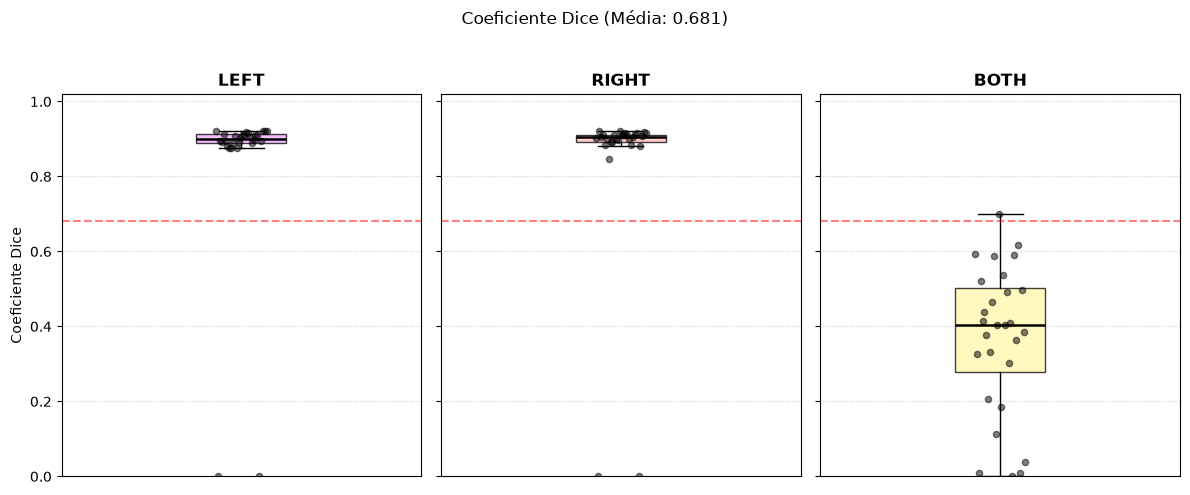

In [ ]:
analises.boxplot("dice")

In [ ]:
outliers = analises.encontrar_outliers("hausdorff")
outliers

[{'i': 11,
  'paciente_id': '011_S_0010',
  'segmentacao': 'both',
  'diagnostico': 'ad',
  'metrica': 'hausdorff',
  'valor': 19.5192},
 {'i': 17,
  'paciente_id': '019_S_4549',
  'segmentacao': 'both',
  'diagnostico': 'ad',
  'metrica': 'hausdorff',
  'valor': 24.779},
 {'i': 38,
  'paciente_id': '007_S_4387',
  'segmentacao': 'both',
  'diagnostico': 'cn',
  'metrica': 'hausdorff',
  'valor': 17.0235},
 {'i': 44,
  'paciente_id': '011_S_0021',
  'segmentacao': 'both',
  'diagnostico': 'cn',
  'metrica': 'hausdorff',
  'valor': 28.2896},
 {'i': 74,
  'paciente_id': '012_S_1321',
  'segmentacao': 'both',
  'diagnostico': 'mci',
  'metrica': 'hausdorff',
  'valor': 20.8327},
 {'i': 3,
  'paciente_id': '007_S_1304',
  'segmentacao': 'left',
  'diagnostico': 'ad',
  'metrica': 'hausdorff',
  'valor': 50.9725},
 {'i': 33,
  'paciente_id': '016_S_4121',
  'segmentacao': 'left',
  'diagnostico': 'cn',
  'metrica': 'hausdorff',
  'valor': 46.7012},
 {'i': 69,
  'paciente_id': '123_S_0108',


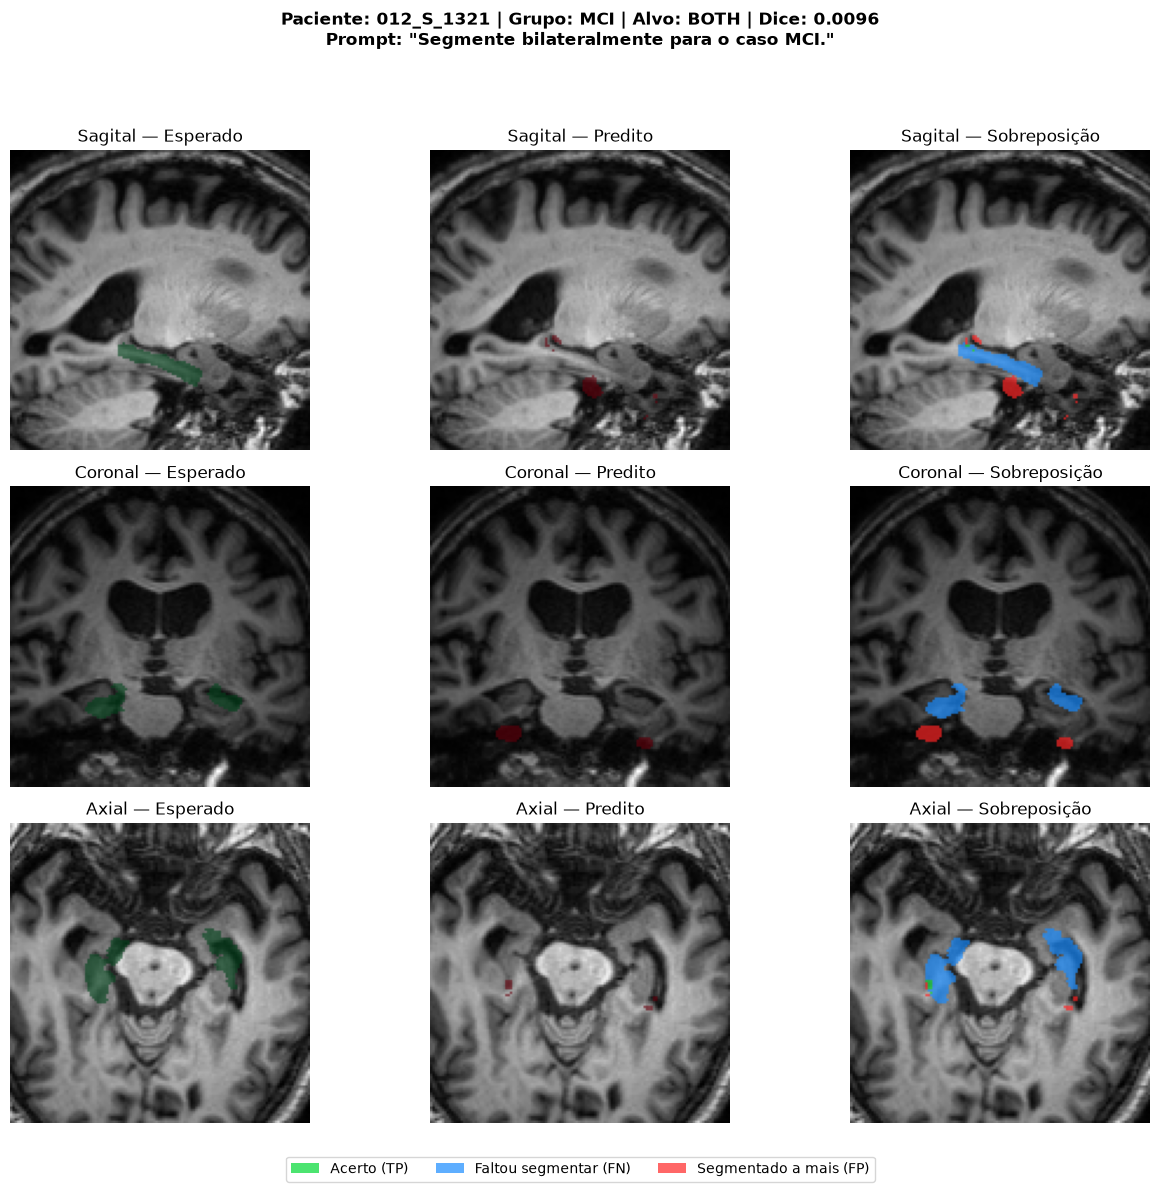

In [ ]:
analises.plotar_comparacao_3d(
    74
)

# BioBERT

In [13]:
hyperparameters = {
    "n_channels": 1,
    "canal_inicial": 32,
    "norm": True,

    "hidden_layer": 256,
    "mlp_dropout": 0.1,
    "n_head": 4,

    "batch_size": 2,
    "learning_rate": 3e-4,
    "weight_decay": 1e-4,
    "peso_dice": 0.9,
    "seed": 125,
    "max_epochs": 200,
    "patience": 50,
    "freeze_text": True,

    "caminho_prompts": "comandos_segmentacao_ingles.csv",
    "text_model": "dmis-lab/biobert-v1.1"
}

In [ ]:
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping
from pytorch_lightning.loggers import CSVLogger

datamodule = Datamodule_Hipocampo(
    path = harp_path,
    hparams = hyperparameters
)
modelo = Treinamento_hipocampo(hyperparameters)

checkpoint_callback = ModelCheckpoint(
    dirpath = "modelo_salvos/",
    filename = "multimodal_hipocampo_biobert_{epoch:02d}_{val_loss:.4f}",
    monitor = "val_loss",
    mode = "min",
    save_top_k = 1
)

early_stopping_callback = EarlyStopping(
    monitor = "val_loss",
    patience = hyperparameters["patience"],
    mode = "min",
    verbose = True
)

logger = CSVLogger("logs_treino/", name = "unet_multimodal_biobert")

trainer = pl.Trainer(
    max_epochs = hyperparameters["max_epochs"],
    accelerator = "gpu" if torch.cuda.is_available() else "cpu",
    devices = 1,
    precision = "16-mixed",
    callbacks = [checkpoint_callback, early_stopping_callback],
    gradient_clip_val = 1.0,
    logger = logger
)

trainer.fit(
    model = modelo,
    train_dataloaders = datamodule.train_dataloader(),
    val_dataloaders = datamodule.val_dataloader()
)

# TESTE!!
print("TESTE!!")

trainer.test(
    model = modelo,
    dataloaders = datamodule.test_dataloader(),
    ckpt_path = "best"
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA GeForce RTX 4060 Laptop GPU') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
C:\Users\joaov\AppData\Local\Programs\Python\Python314\Lib\site-packages\pytorch_lightning\callbacks\model_checkpoint.py:881: Checkpoint directory C:\Users\joaov\Downloads\projeto_final_ia025\modelo_salvos exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0

┏━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name   ┃ Type                ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ modelo │ TextBraTS_hipocampo │  140 M │ train │     0 │
│ 1 │ perda  │ Loss                │      0 │ train │     0 │
└───┴────────┴─────────────────────┴────────┴───────┴───────┘

Trainable params: 32.3 M                                                                                           
Non-trainable params: 108 M                                                                                        
Total params: 140 M                                                                                                
Total estimated model params size (MB): 562.494                                                                    
Modules in train mode: 125                                                                                         
Modules in eval mode: 228                                                                                          
Total FLOPs: 0

Output()

C:\Users\joaov\AppData\Local\Programs\Python\Python314\Lib\site-packages\pytorch_lightning\utilities\_pytree.py:21:
`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` 
instead.

C:\Users\joaov\AppData\Local\Programs\Python\Python314\Lib\site-packages\pytorch_lightning\trainer\connectors\data_
connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing 
the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.

C:\Users\joaov\AppData\Local\Programs\Python\Python314\Lib\site-packages\pytorch_lightning\trainer\connectors\data_
connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing 
the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.

C:\Users\joaov\AppData\Local\Programs\Python\Python314\Lib\site-packages\pytorch_lightning\loops\fit_loop.py:538: 
Found 228 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If
this is intentional, you can ignore this warning.

Metric val_loss improved. New best score: 0.907
Metric val_loss improved by 0.020 >= min_delta = 0.0. New best score: 0.887
Metric val_loss improved by 0.043 >= min_delta = 0.0. New best score: 0.844
Metric val_loss improved by 0.077 >= min_delta = 0.0. New best score: 0.767
Metric val_loss improved by 0.129 >= min_delta = 0.0. New best score: 0.638
Metric val_loss improved by 0.051 >= min_delta = 0.0. New best score: 0.587
Metric val_loss improved by 0.013 >= min_delta = 0.0. New best score: 0.574
Metric val_loss improved by 0.014 >= min_delta = 0.0. New best score: 0.559
Metric val_loss improved by 0.007 >= min_delta = 0.0. New best score: 0.552
Metric val_loss improved by 0.004 >= min_delta = 0.0. New best score: 0.548
Metric val_loss improved by 0.001 >= min_delta = 0.0. New best score: 0.547
Metric val_loss improved by 0.003 >= min_delta = 0.0. New best score: 0.544
Metric val_loss improved by 0.003 >= min_delta = 0.0. New best score: 0.540
